In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import random

import torch
import torch.nn.functional as F
from torchvision import datasets
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

from model import CNN, create_transforms

sns.set_theme()
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Preparation

## Load config and checkpoint

In [2]:
with open(f"hp_configs.json") as f:
    configs = json.load(f)

config = configs[0]["config"]

In [3]:
model = CNN(
    fc_units=config["fc_units"],
    activation=config["activation"],
    dropout=config["dropouts"]
)

In [4]:
checkpoint = torch.load("best_model_checkpoint.pth", weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(DEVICE)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.1)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): LeakyReLU(negative_slope=0.1)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): LeakyReLU(negative_slope=0.1)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Linear(in_features=512, out_features=2, bias=True)
  )
)

## Collect predictions

In [5]:
_, test_tf = create_transforms()

test_dataset = datasets.ImageFolder("data/test", transform=test_tf)
test_loader = DataLoader(test_dataset, batch_size=config["batch_sizes"], shuffle=False)

In [6]:
all_labels = []
all_preds = []
all_probs = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

labels = np.array(all_labels)
preds = np.array(all_preds)
probs = np.array(all_probs)

# Plots and metrics

## Visualize results

In [7]:
class_names = test_dataset.classes

tp_idx = np.where((preds == 1) & (labels == 1))[0]
fp_idx = np.where((preds == 1) & (labels == 0))[0]
tn_idx = np.where((preds == 0) & (labels == 0))[0]
fn_idx = np.where((preds == 0) & (labels == 1))[0]

category_map = {
    "True Positives": tp_idx,
    "False Positives": fp_idx,
    "True Negatives": tn_idx,
    "False Negatives": fn_idx
}

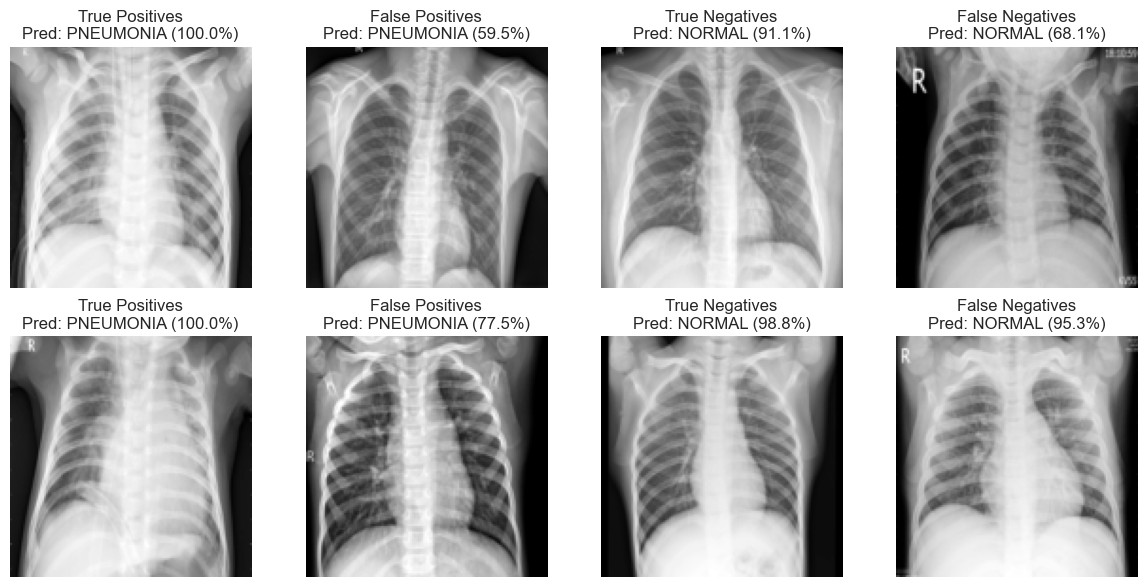

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
categories = ["True Positives", "False Positives", "True Negatives", "False Negatives"]

for i, cat in enumerate(categories):
    indices = category_map[cat]
    selected_indices = np.random.choice(indices, 2, replace=False)

    for j, idx in enumerate(selected_indices):
        img, _ = test_dataset[idx]
        confidence = probs[idx][preds[idx]] * 100
        
        ax[j, i].imshow(img.permute(1, 2, 0).cpu(), cmap='gray')
        ax[j, i].set_title(f"{cat}\nPred: {class_names[preds[idx]]} ({confidence:.1f}%)")
        ax[j, i].axis("off")

plt.tight_layout()
plt.show()

## Confusion Matrix

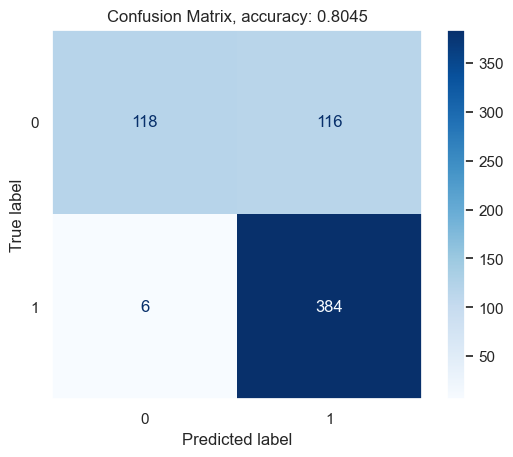

In [9]:
cm = confusion_matrix(labels, preds)
tn, fp = cm[0]
fn, tp = cm[1]
accuracy = (tp + tn) / np.sum(cm)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix, accuracy: {accuracy:.4f}")
plt.grid(visible=False)
plt.show()


## Other metrics

In [10]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1_score = 2 * (precision * recall) / (precision + recall)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1_score:.4f}")

Precision: 0.7680
Recall: 0.9846
F1 score: 0.8629


## ROC curve

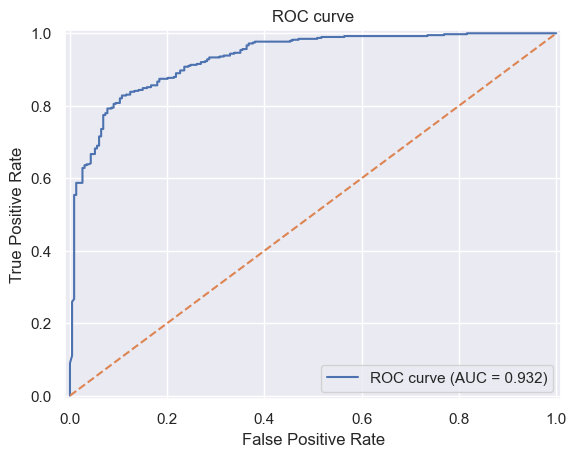

In [11]:
all_probs_pos = probs[:, 1]
fpr, tpr, thresholds = roc_curve(labels, all_probs_pos)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()

# Model performance

In [12]:
full_checkpoint = torch.load("final_checkpoint.pth", weights_only=False)

full_history = full_checkpoint["history"]
full_epoch = full_checkpoint["epoch"]
best_epoch = checkpoint["epoch"]

train_losses = full_history["train_loss"]
train_accs = full_history["train_acc"]
val_accs = full_history["val_acc"]
test_acc = full_history["test_acc"]
all_epochs = range(full_epoch)
test_acc

0.8060897435897436

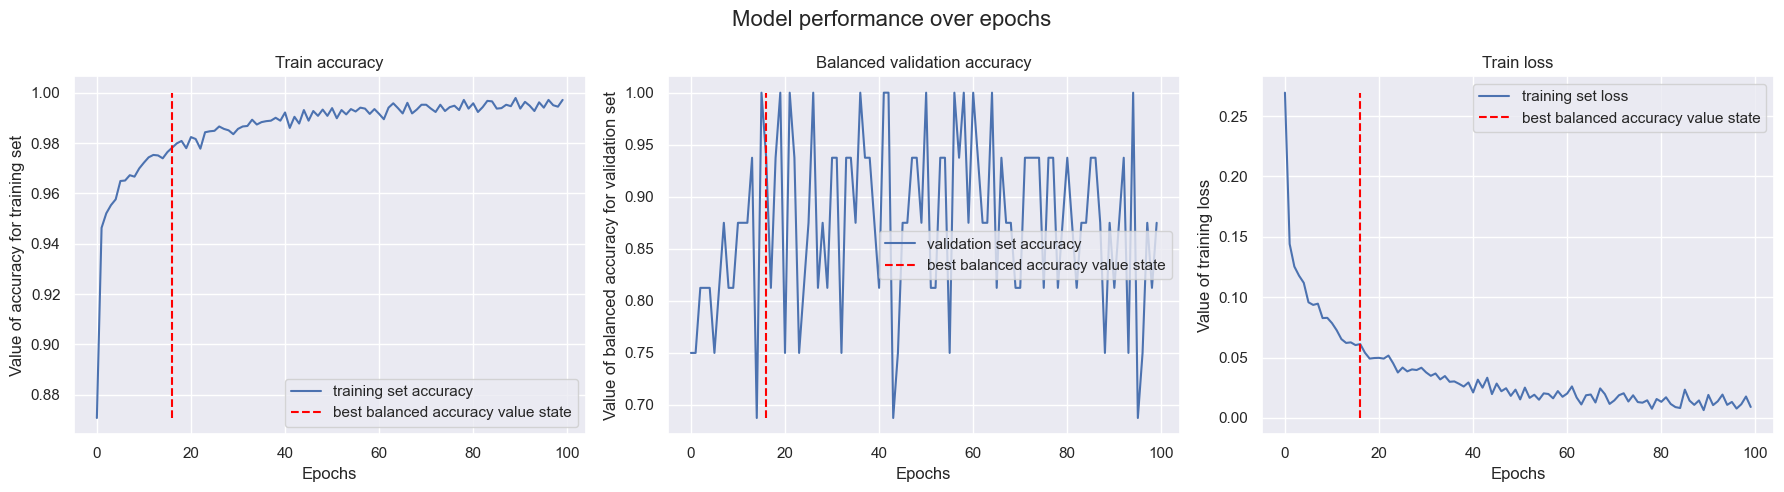

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18,5))
fig.suptitle("Model performance over epochs", fontsize=16)

ax[0].plot(all_epochs, train_accs, label="training set accuracy")
ax[0].vlines(best_epoch, ymin=min(train_accs), ymax=1, 
    linestyle = "--", color="red", label="best balanced accuracy value state"
)
ax[0].set_title("Train accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Value of accuracy for training set")
ax[0].legend()

ax[1].plot(all_epochs, val_accs, label="validation set accuracy")
ax[1].vlines(best_epoch, ymin=min(val_accs), ymax=1, 
    linestyle = "--", color="red", label="best balanced accuracy value state"
)
ax[1].set_title("Balanced validation accuracy")
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Value of balanced accuracy for validation set")
ax[1].legend()

ax[2].plot(all_epochs, train_losses, label="training set loss")
ax[2].vlines(best_epoch, ymin=0, ymax=max(train_losses), 
    linestyle = "--", color="red", label="best balanced accuracy value state"
)
ax[2].set_title("Train loss")
ax[2].set_xlabel("Epochs")
ax[2].set_ylabel("Value of training loss")
ax[2].legend()

plt.tight_layout()
plt.show()